# Batalla Naval como problema de IA: entorno y agentes

Este notebook acompaña la aplicación del proyecto y muestra, paso a paso:

1. Los niveles de dificultad que configuran el entorno.
2. La creación de una instancia del entorno y sus principales.
3. Sus métodos principales**: percepción, acciones, transición, prueba de objetivo, semillas e instancias manuales.
4. La aplicación de cada algoritmo** sobre la misma partida.
5. La comparación de las dos heurísticas de MCTS y de todos los agentes con las métricas del proyecto.


## 1. Preparación

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from render_pygame import RenderizadorPygame
import pygame

from agents import AGENTES
from ambientes import AGUA, DESCONOCIDO, HUNDIDO, TOCADO, BatallaNavalEnv
from comparar import dibujar_comparacion, ejecutar_comparacion, resumen_agentes
from dificultad import NIVELES, ORDEN_NIVELES
from instancia import Instancia
from utils import coord_a_texto

%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90
pd.set_option('display.precision', 2)
SEMILLA = 1000

La función `mostrar` dibuja un tablero con el mismo renderizador de la interfaz y lo muestra con matplotlib.
Con `revelado=True` se ve la flota oculta; `mapa` pinta el mapa de calor de un agente y `numeros`
el orden de los disparos.

In [2]:
render = RenderizadorPygame()


def mostrar(env, revelado=False, mapa=None, numeros=None, titulo=None, ax=None):
    render.configurar(env)
    superficie = render.dibujar(env, revelado, 10_000, mapa=mapa, numeros=numeros)
    imagen = pygame.surfarray.array3d(superficie).swapaxes(0, 1)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.imshow(imagen)
    ax.axis('off')
    if titulo:
        ax.set_title(titulo, fontsize=10)
    return ax

## 2. Niveles de dificultad 

Cada nivel es un `ConfigDificultad` inmutable con el tamaño del tablero, la flota, el límite de disparos,
el ruido del sonar y si se informa qué barcos quedan. `casillas_barco` es el mínimo teórico de disparos
para ganar (una partida perfecta) y `densidad` la fracción del tablero ocupada por barcos.

In [3]:
pd.DataFrame([{
    'nivel': c.nombre,
    'tablero': f"{c.filas}x{c.columnas}",
    'flota': ", ".join(f"{n} ({L})" for n, L in c.flota.items()),
    'mínimo de disparos': c.casillas_barco,
    'densidad': round(c.densidad, 3),
    'límite de disparos': c.max_disparos or 'sin límite',
    'ruido del sonar': c.prob_ruido,
    'flota visible': c.mostrar_flota_restante,
} for c in (NIVELES[k] for k in ORDEN_NIVELES)]).set_index('nivel')

,tablero,flota,mínimo de disparos,densidad,límite de disparos,ruido del sonar,flota visible
nivel,,,,,,,
Fácil,6x6,"Crucero (3), Destructor (2), Lancha (2)",7,0.19,sin límite,0.00,True
Medio,8x8,"Acorazado (4), Crucero (3), Submarino (3), Des...",12,0.19,40,0.00,True
Difícil,10x10,"Portaaviones (5), Acorazado (4), Crucero (3), ...",17,0.17,55,0.00,False
Experto,12x12,"Portaaviones (5), Acorazado (4), Crucero (3), ...",17,0.12,80,0.06,False


## 3. Creación de una instancia del entorno

Se crea un entorno de nivel Medio con una semilla fija. La semilla determina dónde queda la flota:
con la misma semilla se obtiene siempre la misma partida, lo que permite comparar agentes de forma justa.

In [4]:
env = BatallaNavalEnv(config=NIVELES['medio'], seed=SEMILLA)

pd.Series({
    'config.nombre': env.config.nombre,
    'filas x columnas': f"{env.filas} x {env.columnas}",
    'seed': env.seed,
    'flota_config': env.flota_config,
    'turnos': env.turnos,
    'recompensa_acumulada': env.recompensa_acumulada,
    'done / ganado / agotado': (env.done, env.ganado, env.agotado),
    'disparos_restantes()': env.disparos_restantes(),
}, name='valor').to_frame()

,valor
config.nombre,Medio
filas x columnas,8 x 8
seed,1000
flota_config,"{'Acorazado': 4, 'Crucero': 3, 'Submarino': 3,..."
turnos,0
recompensa_acumulada,0
done / ganado / agotado,"(False, False, False)"
disparos_restantes(),40


### Los barcos 

Cada barco es un objeto Barco con su nombre, su longitud, las casillas que ocupa y los impactos recibidos.

In [5]:
pd.DataFrame([{
    'barco': b.nombre,
    'longitud': b.longitud,
    'casillas': " ".join(coord_a_texto(r, c) for r, c in b.posiciones),
    'impactos': b.impactos,
    'hundido': b.esta_hundido(),
} for b in env.barcos])

,barco,longitud,casillas,impactos,hundido
0,Acorazado,4,E2 F2 G2 H2,0,False
1,Crucero,3,B3 B4 B5,0,False
2,Submarino,3,C3 D3 E3,0,False
3,Destructor,2,B6 B7,0,False


### Los dos tableros

El entorno guarda dos matrices del mismo tamaño:

- `tablero_oculto`: la verdad. 0 es agua y 1, 2, 3, ... identifican cada barco. El agente nunca la ve.
- `tablero_agente`: lo que el agente sabe. Empieza en `DESCONOCIDO` (-1) y se llena con
  `AGUA` (0), `TOCADO` (1) y `HUNDIDO` (2) a medida que dispara.

Por eso el problema es parcialmente observable.

tablero_oculto:
 [[0 0 0 0 0 0 0 0]
 [0 0 0 0 1 1 1 1]
 [0 2 3 3 3 0 0 0]
 [0 2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

tablero_agente:
 [[-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]]


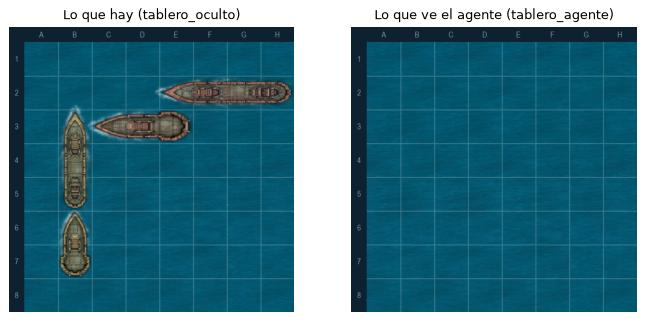

In [6]:
print("tablero_oculto:\n", env.tablero_oculto)
print("\ntablero_agente:\n", env.tablero_agente)

fig, ejes = plt.subplots(1, 2, figsize=(9, 4.5))
mostrar(env, revelado=True, titulo="Lo que hay (tablero_oculto)", ax=ejes[0])
mostrar(env, revelado=False, titulo="Lo que ve el agente (tablero_agente)", ax=ejes[1])
plt.show()

## 4. Métodos principales del entorno

### 4.1 Acciones aplicables y percepción

- `acciones_aplicables()` devuelve las casillas a las que aún no se ha disparado: el conjunto de acciones *A*.
- `para_sentidos()` devuelve la observación: lo único que un agente puede usar para decidir.

In [7]:
acciones = env.acciones_aplicables()
print(f"Acciones aplicables: {len(acciones)} (todas las casillas del tablero)")
print("Primeras:", [coord_a_texto(*a) for a in acciones[:6]], "...")

obs = env.para_sentidos()
{k: (v if k != 'tablero_agente' else f"matriz {v.shape}") for k, v in obs.items()}

Acciones aplicables: 64 (todas las casillas del tablero)
Primeras: ['A1', 'B1', 'C1', 'D1', 'E1', 'F1'] ...


{'tablero_agente': 'matriz (8, 8)',
 'barcos_vivos': ['Acorazado', 'Crucero', 'Submarino', 'Destructor'],
 'n_barcos_vivos': 4,
 'ultimo_feedback': None,
 'turnos': 0,
 'disparos_restantes': 40}

### 4.2 La transición: 

`step` ejecuta un disparo y devuelve `(observación, recompensa, done, info)`. Cada disparo cuesta **-1**,
así que maximizar la recompensa equivale a ganar con la menor cantidad de disparos.

Para mostrar los tres resultados posibles se dispara al agua y luego a todas las casillas del barco más
corto. Se usa el tablero oculto solo para elegir las casillas de esta demostración; un agente no puede hacerlo.

Disparo a A1: agua     | recompensa -1 | acumulada -1 | restantes 39
Disparo a B6: impacto  | recompensa -1 | acumulada -2 | restantes 38
Disparo a B7: hundido  | recompensa -1 | acumulada -3 | restantes 37

Barcos vivos según la observación: ['Acorazado', 'Crucero', 'Submarino']


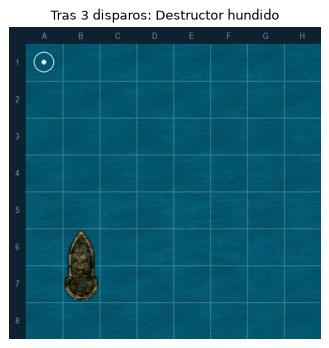

In [8]:
barco = min(env.barcos, key=lambda b: b.longitud)
agua = next((r, c) for r, c in env.acciones_aplicables() if env.tablero_oculto[r, c] == 0)

for accion in [agua] + barco.posiciones:
    obs, recompensa, done, info = env.step(accion)
    print(f"Disparo a {coord_a_texto(*accion)}: {obs['ultimo_feedback']['resultado']:8s}"
          f" | recompensa {recompensa} | acumulada {env.recompensa_acumulada}"
          f" | restantes {env.disparos_restantes()}")

print("\nBarcos vivos según la observación:", obs['barcos_vivos'])
mostrar(env, titulo=f"Tras {env.turnos} disparos: {barco.nombre} hundido")
plt.show()

Al hundir un barco, **todas** sus casillas pasan a `HUNDIDO` (2) en el tablero del agente:

In [9]:
env.tablero_agente

array([[ 0, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1],
       [-1,  2, -1, -1, -1, -1, -1, -1],
       [-1,  2, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1]])

### 4.3 Prueba de objetivo y fin de partida

`test_objetivo()` es verdadero cuando toda la flota está hundida (`ganado`). La partida también termina,
con derrota, si se agotan los disparos (`agotado`). `done` es cualquiera de los dos.
Aquí se termina la partida disparando a todos los barcos que quedan.

In [10]:
print("¿Objetivo cumplido?", env.test_objetivo())
for b in env.barcos:
    for casilla in b.posiciones:
        if env.tablero_agente[casilla] == DESCONOCIDO:
            env.step(casilla)

print("¿Objetivo cumplido?", env.test_objetivo(),
      f"| done={env.done}, ganado={env.ganado}, agotado={env.agotado}")
print(f"Disparos: {env.turnos} (el mínimo era {env.config.casillas_barco}),"
      f" recompensa acumulada {env.recompensa_acumulada}")

¿Objetivo cumplido? False
¿Objetivo cumplido? True | done=True, ganado=True, agotado=False
Disparos: 13 (el mínimo era 12), recompensa acumulada -13


### 4.4 reset y la semilla

`reset(seed)` reinicia el entorno. Con la misma semilla la flota queda exactamente en el mismo lugar;
con otra semilla cambia.

In [21]:
env.reset(seed=SEMILLA)
misma = BatallaNavalEnv(config=NIVELES['medio'], seed=SEMILLA)
otra = BatallaNavalEnv(config=NIVELES['medio'], seed=SEMILLA + 1)

print("Tras reset: turnos =", env.turnos, "| done =", env.done)
print("¿Misma flota con la misma semilla?", np.array_equal(env.tablero_oculto, misma.tablero_oculto))
print("¿Misma flota con otra semilla?   ", np.array_equal(env.tablero_oculto, otra.tablero_oculto))

Tras reset: turnos = 0 | done = False
¿Misma flota con la misma semilla? True
¿Misma flota con otra semilla?    False


### 4.5 Instancias personalizadas: colocar la flota a mano

Además de los niveles, el entorno acepta una **disposición manual** de la flota:
una lista `(barco, fila, columna, 'H'|'V')`. `validar_posicion` comprueba si un barco cabe sin salirse ni
cruzarse con otro. La clase `Instancia` (`instancia.py`) junta configuración y disposición; es lo que crea
el *Editor de instancias* de la interfaz y se puede guardar en JSON.

¿Cabe un barco de 4 en E7, horizontal? True
¿Cabe un barco de 4 en A1, vertical?   False (choca con el Acorazado)
¿Cabe un barco de 4 en G7, horizontal? False (se sale del tablero)
¿reset conserva la flota manual?      True


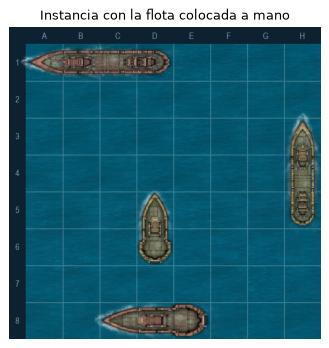

In [12]:
disposicion = [('Acorazado', 0, 0, 'H'), ('Crucero', 2, 7, 'V'),
               ('Submarino', 7, 2, 'H'), ('Destructor', 4, 3, 'V')]
manual = Instancia(config=NIVELES['medio'], disposicion=disposicion)
env_manual = manual.crear_env(seed=SEMILLA)

print("¿Cabe un barco de 4 en E7, horizontal?", env_manual.validar_posicion(6, 4, 4, 'H'))
print("¿Cabe un barco de 4 en A1, vertical?  ", env_manual.validar_posicion(0, 0, 4, 'V'), "(choca con el Acorazado)")
print("¿Cabe un barco de 4 en G7, horizontal?", env_manual.validar_posicion(6, 6, 4, 'H'), "(se sale del tablero)")

env_manual.reset(seed=SEMILLA + 99)
print("¿reset conserva la flota manual?     ", env_manual.disposicion_actual() == disposicion)
mostrar(env_manual, revelado=True, titulo="Instancia con la flota colocada a mano")
plt.show()

### 4.6 Ruido del sonar (nivel Experto)

En Experto, con probabilidad `prob_ruido` el sonar **reporta mal** un disparo (agua ↔ impacto); el hundido
siempre es verdadero. `info['resultado_real']` guarda lo que pasó de verdad (solo para registro: los agentes
no lo ven). Se juega una partida al azar para contar cuántas veces mintió el sonar.

In [13]:
env_ruido = BatallaNavalEnv(config=NIVELES['experto'], seed=SEMILLA)
rng = np.random.default_rng(0)
errores = 0
while not env_ruido.done:
    acciones = env_ruido.acciones_aplicables()
    obs, _, _, info = env_ruido.step(acciones[rng.integers(len(acciones))])
    errores += obs['ultimo_feedback']['resultado'] != info['resultado_real']

print(f"Disparos: {env_ruido.turnos} | reportes falsos: {errores}"
      f" ({errores / env_ruido.turnos:.1%}; prob_ruido = {NIVELES['experto'].prob_ruido:.0%})")

Disparos: 80 | reportes falsos: 7 (8.8%; prob_ruido = 6%)


## 5. Los agentes

Todos los agentes heredan de `Agente` (`agents.py`) y comparten la misma interfaz:

- `restart(seed)`: reinicia el agente al empezar una partida.
- `make_decision(percepts)`: recibe la observación de `para_sentidos()` y devuelve la casilla a disparar.
- `estado_interno()`: describe la última decisión (mapa de calor, contadores, nodos y memoria).

El diccionario `AGENTES` es el registro que usan la interfaz, `evaluar.py` y `comparar.py`.

In [14]:
pd.DataFrame([{
    'clave': clave,
    'nombre': clase().name,
    'clase': clase.__name__,
    'archivo': clase.__module__ + '.py',
} for clave, clase in AGENTES.items()]).set_index('clave')

,nombre,clase,archivo
clave,,,
aleatorio,RandomAgent,RandomAgent,agents.py
caza,Caza-Remate,AgenteCazaRemate,agents.py
dqn,DQN,AgenteDQN,dqn_agent.py
mcts,MCTS (Paridad+Colineal),AgenteMCTS,mcts_agent.py
mcts_vecindad,MCTS (Vecindad),AgenteMCTSVecindad,mcts_agent.py
bayes,Red Bayesiana,AgenteBayesiano,bayes_agent.py


| Agente | Tipo | Idea |
|---|---|---|
| Aleatorio | No informado | Dispara a cualquier casilla desconocida. Es la línea base. |
| Caza-Remate | Informado (reglas heurísticas) | Caza por paridad de ajedrez; al tocar un barco remata sus vecinas, priorizando las alineadas. |
| DQN | Aprendizaje por refuerzo | Una red convolucional entrenada asigna un valor Q a cada casilla y elige la mayor. |
| MCTS (Paridad+Colineal) | Búsqueda en árbol Monte Carlo (POMCP) | Imagina flotas coherentes con lo observado, simula disparos y elige el más visitado. Poda con paridad y colinealidad. |
| MCTS (Vecindad) | Igual, con otra heurística | Solo considera las vecinas ortogonales de los impactos, sin paridad ni colinealidad. |
| Red Bayesiana | Inferencia probabilística | Calcula la probabilidad de barco en cada casilla marginalizando las posiciones posibles de cada barco (Noisy-OR) y dispara a la de mayor probabilidad. |

### 5.1 El ciclo percepción → decisión → acción

Así juega cualquier agente: percibe, decide y el entorno ejecuta. Es el mismo ciclo que usan la interfaz
y `evaluar.py`.

In [15]:
def jugar(clave, instancia, seed):
    agente = AGENTES[clave](config=instancia.config)
    env = instancia.crear_env(seed=seed)
    agente.restart(seed=seed)
    obs = env.para_sentidos()
    orden = {}
    while not env.done:
        accion = agente.make_decision(obs)
        obs, _, _, _ = env.step(accion)
        orden[tuple(int(v) for v in accion)] = env.turnos
    return agente, env, orden

### 5.2 Todos los agentes sobre la misma partida

Cada agente juega la misma instancia (nivel Medio, misma semilla, misma flota). Los números indican el
orden de los disparos; el mínimo posible es 12.

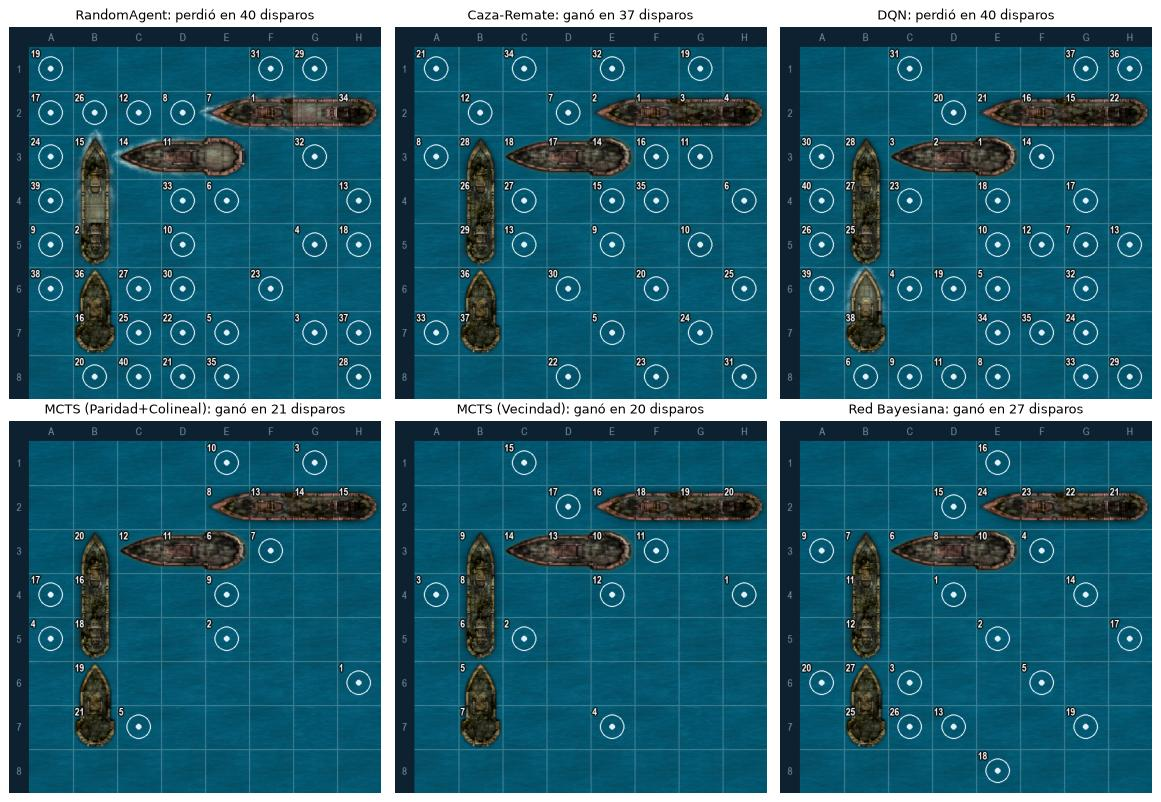

In [16]:
medio = Instancia.de_nivel('medio')
claves = list(AGENTES)
fig, ejes = plt.subplots(2, 3, figsize=(13, 9))
for ax, clave in zip(ejes.flat, claves):
    agente, env_fin, orden = jugar(clave, medio, SEMILLA)
    resultado = "ganó" if env_fin.ganado else "perdió"
    mostrar(env_fin, revelado=True, numeros=orden, ax=ax,
            titulo=f"{agente.name}: {resultado} en {env_fin.turnos} disparos")
for ax in ejes.flat[len(claves):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5.3 Qué "piensa" cada agente

Se juegan los mismos 14 primeros disparos y, en el turno 15, se le pide a cada agente su decisión. El mapa de
calor es `estado_interno()['mapa']`: lo que el agente valora en cada casilla (puntaje, probabilidad o valor Q).
La tabla muestra sus contadores internos.

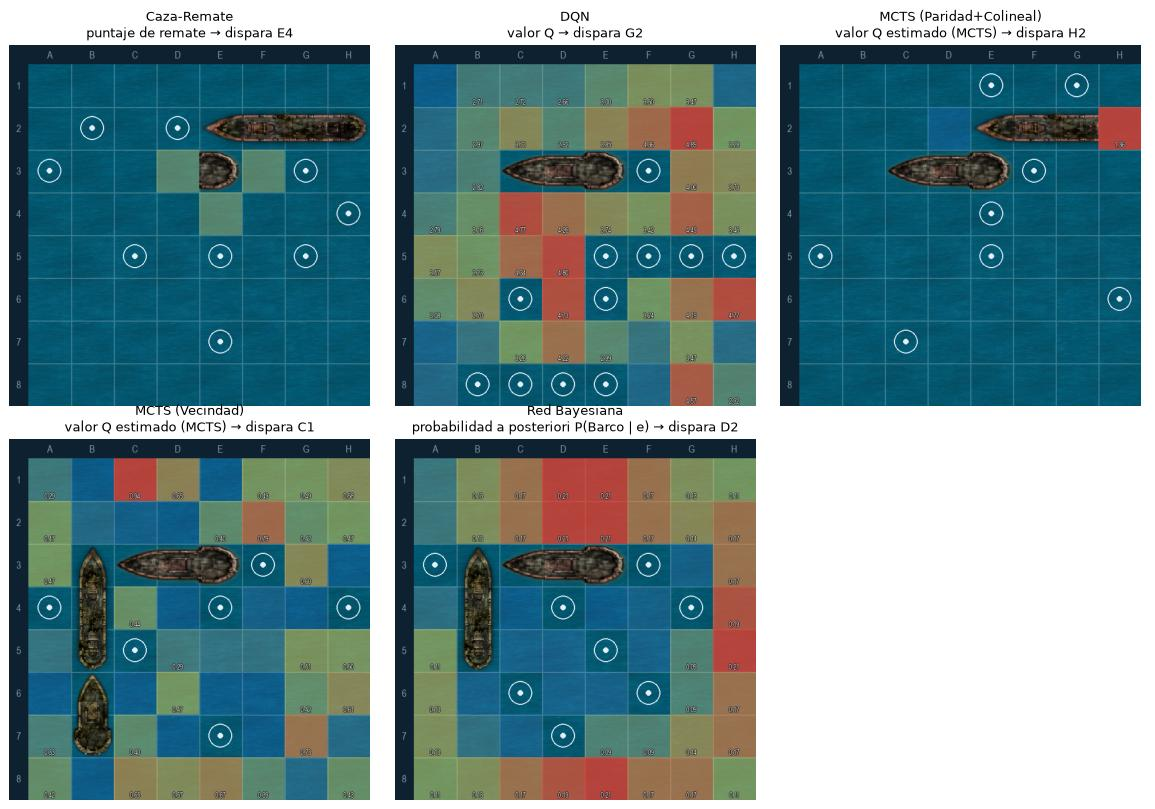

,decisión,nodos generados,nodos expandidos,memoria,detalle
agente,,,,,
Caza-Remate,E4,3,1,3,"modo: remate; candidatas: 3; regla activada: Remate ortogonal simple; candidatas de ""Remate ortogonal simple"": 3"
DQN,G2,50,1,113217,Q maximo: 4.886; Q medio: 3.355; parametros de la red: 113217
MCTS (Paridad+Colineal),H2,147,39,147,simulaciones: 200; candidatas exploradas: 2; nodos en el arbol: 147; acción elegida: H2; nodos expandidos: 39; nodos en frontera: 108; heuristica: paridad_colineal
MCTS (Vecindad),C1,201,54,201,simulaciones: 200; candidatas exploradas: 50; nodos en el arbol: 201; acción elegida: C1; nodos expandidos: 54; nodos en frontera: 147; heuristica: vecindad
Red Bayesiana,D2,192,89,153,P maxima: 0.2051; hipotesis evaluadas: 89; barcos en red: 2


In [17]:
def pensar(clave, instancia, seed, disparos_previos=14):
    agente = AGENTES[clave](config=instancia.config)
    env = instancia.crear_env(seed=seed)
    agente.restart(seed=seed)
    obs = env.para_sentidos()
    for _ in range(disparos_previos):
        obs, _, _, _ = env.step(agente.make_decision(obs))
    accion = agente.make_decision(obs)
    return agente, env, accion, agente.estado_interno()


inteligentes = [k for k in claves if k != 'aleatorio']
fig, ejes = plt.subplots(2, 3, figsize=(13, 9))
filas = []
for ax, clave in zip(ejes.flat, inteligentes):
    agente, env_t, accion, interno = pensar(clave, medio, SEMILLA)
    mostrar(env_t, mapa=interno['mapa'], ax=ax,
            titulo=f"{agente.name}\n{interno['tipo_mapa']} → dispara {coord_a_texto(*accion)}")
    filas.append({'agente': agente.name,
                  'decisión': coord_a_texto(*accion),
                  'nodos generados': interno.get('nodos_generados'),
                  'nodos expandidos': interno.get('nodos_expandidos'),
                  'memoria': interno.get('memoria'),
                  'detalle': "; ".join(f"{k}: {v}" for k, v in interno['info'].items())})
for ax in ejes.flat[len(inteligentes):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
pd.set_option('display.max_colwidth', None)
pd.DataFrame(filas).set_index('agente')

### 5.4 Dos heurísticas para MCTS

Ambos agentes son el mismo algoritmo (`AgenteMCTS`) con una heurística distinta para elegir qué disparos
explorar en el árbol:

- **Paridad + colineal**: prioriza las casillas que continúan una línea de impactos y, si no hay impactos,
  explora solo casillas de paridad (como un tablero de ajedrez).
- **Vecindad**: solo las vecinas ortogonales de los impactos; sin impactos, cualquier casilla libre.

Se comparan sobre las mismas 5 partidas de nivel Medio con `ejecutar_comparacion` de `comparar.py`.

In [18]:
df_heur, errores = ejecutar_comparacion(['mcts', 'mcts_vecindad'], medio, n=5, seed_base=SEMILLA)
resumen_agentes(df_heur)[['Victorias (%)', 'Disparos (media)', 'Disparos (desv.)', 'Eficiencia',
                          'Brecha al óptimo', 'Tiempo/jugada (ms)']]

,Victorias (%),Disparos (media),Disparos (desv.),Eficiencia,Brecha al óptimo,Tiempo/jugada (ms)
nombre,,,,,,
MCTS (Paridad+Colineal),100.0,25.8,4.53,0.48,13.8,109.86
MCTS (Vecindad),100.0,27.2,5.84,0.46,15.2,104.43


## 6. Comparación de todos los agentes

La pestaña **Comparar** de la interfaz usa exactamente estas funciones. Todos los agentes juegan las mismas
partidas: la partida *i* usa la semilla `SEMILLA + i`. Aquí se usan 5 partidas para que el notebook sea rápido;
para el análisis del informe conviene usar más (por ejemplo `python evaluar.py --episodios 100`).

In [19]:
df, errores = ejecutar_comparacion(claves, medio, n=5, seed_base=SEMILLA)
if errores:
    print("No se pudieron evaluar:", errores)
tabla = resumen_agentes(df)
tabla

,Partidas,Victorias (%),Disparos (media),Disparos (desv.),Disparos (mín.),Disparos (máx.),Eficiencia,Óptimas (%),Brecha al óptimo,Recompensa acum.,Tiempo/jugada (ms),Tiempo/partida (s),Evaluaciones,Memoria máx.,Tiempo CPU (s),Nodos generados,Nodos expandidos
nombre,,,,,,,,,,,,,,,,,
RandomAgent,5,0.0,40.0,0.00,40,40,NaN,0.0,NaN,-40.0,0.08,3.09e-03,0.0,0,3.13e-03,0.0,0.0
Caza-Remate,5,100.0,37.6,1.36,36,40,0.32,0.0,25.6,-37.6,0.07,2.58e-03,505.0,32,3.13e-03,505.0,42.8
DQN,5,40.0,38.6,2.33,34,40,0.33,0.0,24.5,-38.6,0.47,1.80e-02,1742.0,113217,1.63e-01,1742.0,38.6
MCTS (Paridad+Colineal),5,100.0,25.8,4.53,21,33,0.48,0.0,13.8,-25.8,108.39,2.79e+00,34666.2,201,3.04e+00,4147.4,823.4
MCTS (Vecindad),5,100.0,27.2,5.84,20,37,0.46,0.0,15.2,-27.2,99.67,2.72e+00,35444.0,201,2.70e+00,4782.8,1336.0
Red Bayesiana,5,100.0,30.4,3.67,27,37,0.40,0.0,18.4,-30.4,0.86,2.61e-02,4404.0,448,2.81e-02,7814.4,4404.0


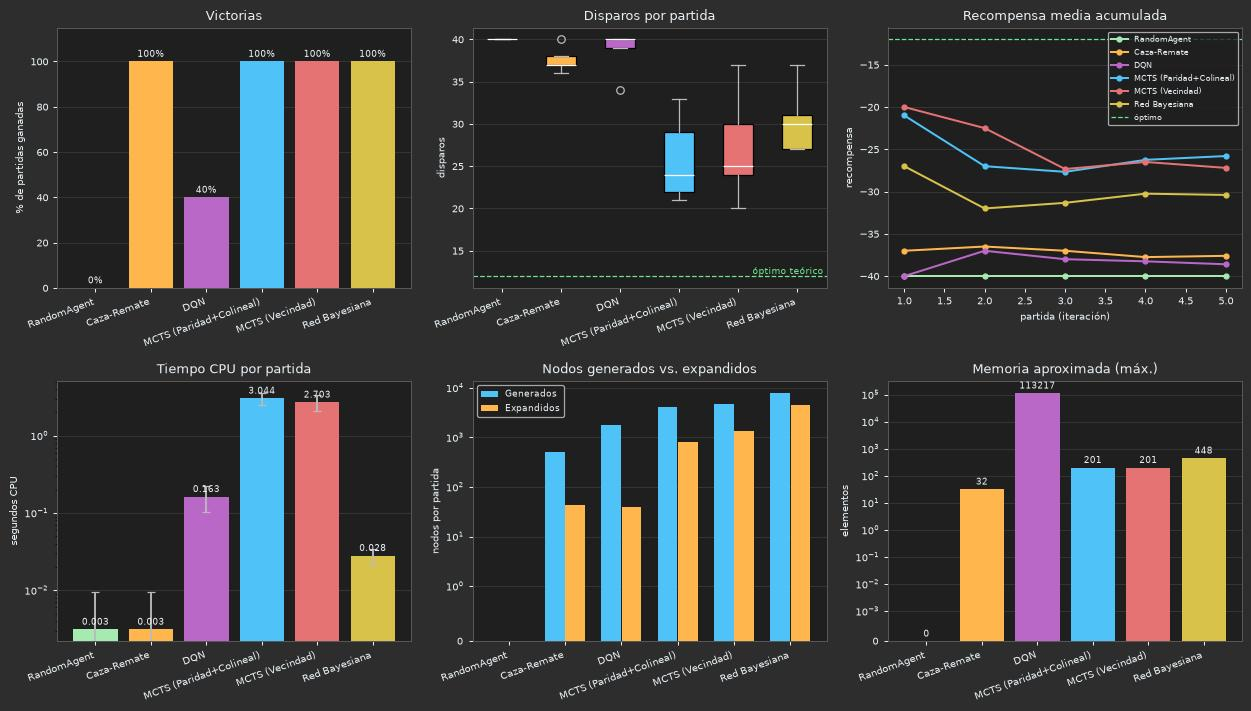

In [20]:
fig = plt.figure(figsize=(14, 8))
dibujar_comparacion(fig, df, minimo=medio.config.casillas_barco)
plt.show()

## 7. Resumen

- El entorno es **secuencial, discreto, estático y parcialmente observable**; en Experto la observación es
  además **estocástica** por el ruido del sonar.
- `para_sentidos()` es la única información de los agentes, `step()` es la transición con recompensa -1 por
  disparo y `test_objetivo()` comprueba que la flota esté hundida.
- La semilla y la clase `Instancia` permiten repetir exactamente una partida, por eso la comparación es justa.
- Todos los agentes comparten la interfaz `restart` / `make_decision` / `estado_interno`, y se comparan con
  las mismas métricas que la interfaz gráfica (`evaluar.py` y `comparar.py`).

Para ver el proceso animado, paso a paso y con el árbol de MCTS, ejecuta `python app_qt.py`.